<a href="https://colab.research.google.com/github/SeoulTechPSE/tong_lectures/blob/main/4_fields_particles/standard_model/sm_ch03_figures.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

*The Standard Model* — `sm_ch03_figures.ipynb` · after D. Tong's Cambridge lecture notes · Kee-Youn Yoo, Process Systems Laboratory, SeoulTech

# Standard Model Ch 3 Figures — Colab Notebook
**The Standard Model · Chapter 3: The Strong Force**

Tong (DAMTP, Cambridge) · Run each cell to generate figures.
Output: `figures/ch03/fig0N_*.png`

| Figure | Section | Content |
|--------|---------|--------|
| fig01  | §3.2    | Running coupling $\alpha_s(\mu)$: one-loop RGE solution with experimental data points |
| fig02  | §3.3    | Chiral symmetry breaking: $SU(2)_L\times SU(2)_R\to SU(2)_V$, pion as Goldstone boson |
| fig03  | §3.4    | QCD potential $V(r) = -4\alpha_s/3r + \sigma r$ and hadron spectrum schematic |

## Setup — dark palette & output directory

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.patheffects as pe
from matplotlib.patches import FancyArrowPatch, Circle, FancyBboxPatch, Wedge
from matplotlib.lines import Line2D
from matplotlib.colors import to_rgba
import os

# ── Dark palette ─────────────────────────────────────────────────────────────
BG     = '#1e1e2e'
FG     = '#cdd6f4'
EDGE   = '#45475a'
TEAL   = '#2ec4b6'
BLUE   = '#7ec8e3'
YELLOW = '#f9c74f'
GREEN  = '#90ee90'
RED    = '#e07070'
PURPLE = '#c792ea'
ORANGE = '#e8a838'

def hex_alpha(hexcol, alpha=0.13):
    """RGBA tuple from hex colour + alpha — safe for FancyBboxPatch facecolor."""
    r, g, b, _ = to_rgba(hexcol)
    return (r, g, b, alpha)

plt.rcParams.update({
    'figure.facecolor'   : BG,
    'axes.facecolor'     : BG,
    'text.color'         : FG,
    'axes.labelcolor'    : FG,
    'xtick.color'        : FG,
    'ytick.color'        : FG,
    'axes.edgecolor'     : EDGE,
    'grid.color'         : EDGE,
    'grid.alpha'         : 0.3,
    'font.size'          : 12,
    'axes.titlesize'     : 13,
    'axes.titleweight'   : 'bold',
    'axes.titlecolor'    : TEAL,
    'legend.framealpha'  : 0.3,
    'legend.edgecolor'   : EDGE,
    'xtick.major.size'   : 4,
    'ytick.major.size'   : 4,
    'xtick.minor.visible': True,
    'ytick.minor.visible': True,
    'axes.linewidth'     : 1.2,
    'lines.linewidth'    : 2.2,
    'figure.dpi'         : 110,
})

OUTDIR = 'figures/ch03'
os.makedirs(OUTDIR, exist_ok=True)

def save(name, fig=None):
    f = fig or plt.gcf()
    path = f'{OUTDIR}/{name}'
    f.savefig(path, dpi=180, bbox_inches='tight', facecolor=BG)
    print(f'  saved -> {path}')
    plt.show()

print('Setup complete.')


Setup complete.


---
## fig01 · Running Coupling $\alpha_s(\mu)$ (§3.2)

**Left**: One-loop running $\alpha_s(\mu)$ vs energy scale $\mu$, with $\Lambda_{\rm QCD}$ marked  
**Middle**: $\beta$-function decomposition — fermion (screening) vs gluon (anti-screening) contributions  
**Right**: Comparison of QED ($\beta>0$, Landau pole) vs QCD ($\beta<0$, asymptotic freedom)

  saved -> figures/ch03/fig01_running_coupling.png


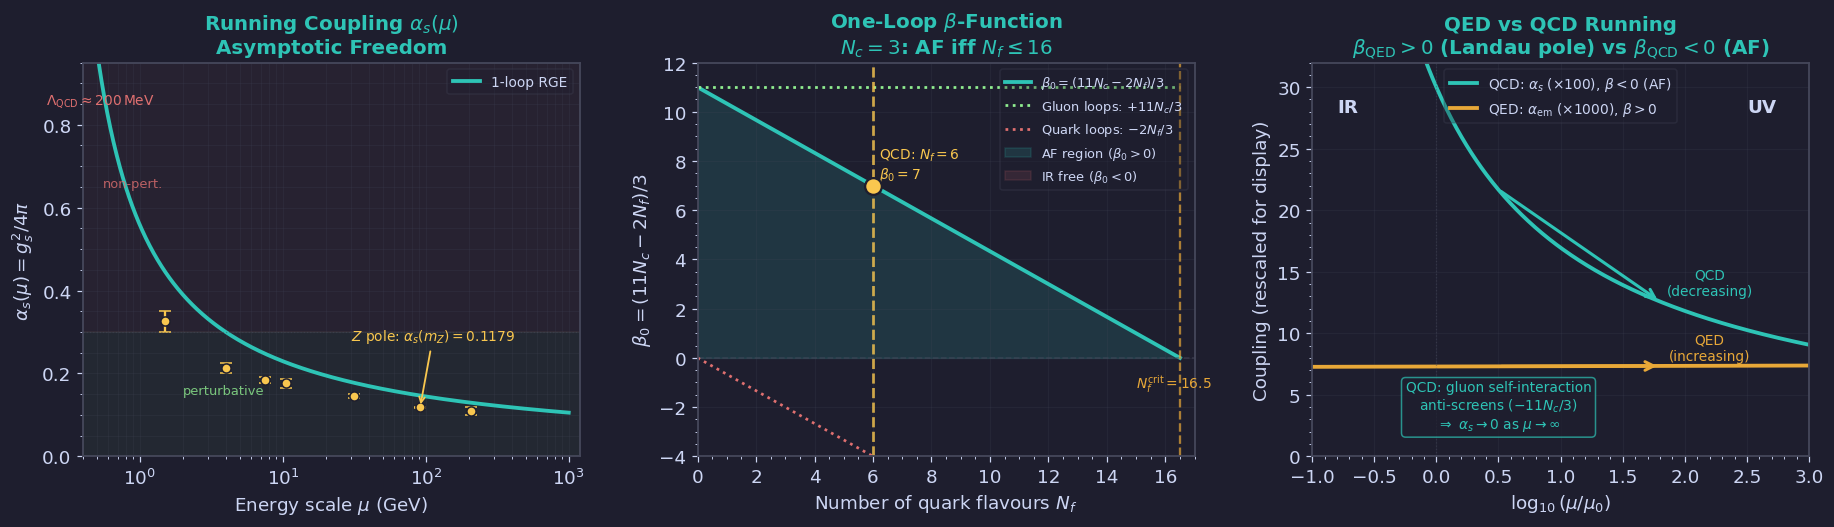

In [2]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))
fig.patch.set_facecolor(BG)

# QCD parameters
Nc    = 3
Nf    = 6
beta0 = (11*Nc - 2*Nf) / 3
beta1 = (34*Nc**2 - 13*Nc*Nf + 3*Nf/Nc) / 3
Lambda_QCD = 0.2   # GeV

def alpha_s_1loop(mu):
    t = np.log(mu / Lambda_QCD)
    return 2 * np.pi / (beta0 * t)

data = [
    (1.5,   0.326, 0.025, r'$\tau$ decay'),
    (4.0,   0.214, 0.012, r'$\Upsilon(1S)$'),
    (7.5,   0.185, 0.007, r'DIS (HERA)'),
    (10.5,  0.176, 0.010, r'$e^+e^-$ (CLEO)'),
    (31.6,  0.145, 0.005, r'$e^+e^-$ (JADE)'),
    (91.2,  0.1179,0.0010,r'$Z$ pole (LEP)'),
    (206.0, 0.110, 0.010, r'$e^+e^-$ (LEP2)'),
]

# ── Left ─────────────────────────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)
mu_range  = np.logspace(np.log10(0.5), np.log10(1000), 600)
mask      = mu_range > Lambda_QCD * 1.3
alpha_vals = np.where(mask, alpha_s_1loop(np.where(mask, mu_range, 1.0)), np.nan)
alpha_vals = np.where(alpha_vals < 1.0, alpha_vals, np.nan)

ax.plot(mu_range, alpha_vals, color=TEAL, lw=2.5, label='1-loop RGE')

for (mu, aval, err, lbl) in data:
    ax.errorbar(mu, aval, yerr=err, fmt='o', color=YELLOW,
                markersize=6, capsize=4, elinewidth=1.5,
                markeredgecolor=BG, markeredgewidth=1)

ax.annotate(r'$Z$ pole: $\alpha_s(m_Z)=0.1179$',
            xy=(91.2, 0.1179), xytext=(30, 0.28),
            color=YELLOW, fontsize=9,
            arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.2))

ax.axvline(Lambda_QCD, color=RED, lw=1.5, ls='--', alpha=0.8)
ax.text(Lambda_QCD*1.1, 0.88, r'$\Lambda_{\rm QCD}\approx200\,{\rm MeV}$',
        color=RED, fontsize=9, va='top')
ax.axhspan(0, 0.3,   alpha=0.05, color=GREEN)
ax.axhspan(0.3, 1.0, alpha=0.05, color=RED)
ax.text(2.0, 0.15, 'perturbative',  color=GREEN,  fontsize=8.5, alpha=0.8)
ax.text(0.55, 0.65, 'non-pert.',     color=RED,    fontsize=8.5, alpha=0.8)
ax.axhline(0.3, color=EDGE, lw=0.8, ls=':', alpha=0.5)

ax.set_xscale('log')
ax.set_xlabel(r'Energy scale $\mu$ (GeV)')
ax.set_ylabel(r'$\alpha_s(\mu) = g_s^2/4\pi$')
ax.set_title(r'Running Coupling $\alpha_s(\mu)$' + '\n' + 'Asymptotic Freedom', color=TEAL)
ax.set_xlim(0.4, 1200)
ax.set_ylim(0, 0.95)
ax.legend(fontsize=9, labelcolor=FG)
ax.grid(True, alpha=0.2, which='both')

# ── Middle ────────────────────────────────────────────────────────────────────
ax2 = axes[1]
ax2.set_facecolor(BG)
Nf_range     = np.linspace(0, 16.5, 300)
beta0_range  = (11*Nc - 2*Nf_range) / 3
ax2.plot(Nf_range, beta0_range, color=TEAL, lw=2.5,
         label=r'$\beta_0 = (11N_c - 2N_f)/3$')
ax2.axhline(0, color=EDGE, lw=1.0, ls='--', alpha=0.6)
ax2.plot(Nf_range, 11*Nc/3 * np.ones_like(Nf_range), color=GREEN, lw=1.8, ls=':',
         label=r'Gluon loops: $+11N_c/3$')
ax2.plot(Nf_range, -2*Nf_range/3, color=RED, lw=1.8, ls=':',
         label=r'Quark loops: $-2N_f/3$')
ax2.fill_between(Nf_range, 0, beta0_range, where=beta0_range>0,
                 color=TEAL, alpha=0.15, label=r'AF region ($\beta_0>0$)')
ax2.fill_between(Nf_range, beta0_range, 0, where=beta0_range<0,
                 color=RED, alpha=0.12, label=r'IR free ($\beta_0<0$)')
Nf_crit = 11*Nc/2
ax2.axvline(6,       color=YELLOW, lw=1.8, ls='--', alpha=0.8)
ax2.axvline(Nf_crit, color=ORANGE, lw=1.5, ls='--', alpha=0.7)
ax2.scatter([6], [beta0], s=120, color=YELLOW, zorder=5, edgecolors=BG, lw=1.5)
ax2.text(6.2, beta0+0.3, f'QCD: $N_f=6$\n$\\beta_0={beta0:.0f}$',
         color=YELLOW, fontsize=9)
ax2.text(Nf_crit-1.5, -1.2, f'$N_f^{{\\rm crit}}={Nf_crit:.1f}$',
         color=ORANGE, fontsize=9)
ax2.set_xlabel(r'Number of quark flavours $N_f$')
ax2.set_ylabel(r'$\beta_0 = (11N_c - 2N_f)/3$')
ax2.set_title(r'One-Loop $\beta$-Function' + '\n' +
              r'$N_c=3$: AF iff $N_f \leq 16$', color=TEAL)
ax2.set_xlim(0, 17);  ax2.set_ylim(-4, 12)
ax2.legend(fontsize=8.5, labelcolor=FG, loc='upper right')
ax2.grid(True, alpha=0.2)

# ── Right ─────────────────────────────────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)
mu_log    = np.linspace(-1, 3, 500)
alpha_QED = 1/137.0 / (1 - 2/(3*np.pi) * (1/137.0) * mu_log * np.log(10))
alpha_QED = np.where(alpha_QED > 0, alpha_QED, np.nan)
alpha_s0  = 0.3
alpha_QCD = alpha_s0 / (1 + beta0/(2*np.pi) * alpha_s0 * mu_log * np.log(10))
alpha_QCD = np.where(alpha_QCD > 0, alpha_QCD, np.nan)

ax3.plot(mu_log, alpha_QCD*100,  color=TEAL,   lw=2.5,
         label=r'QCD: $\alpha_s$ ($\times100$), $\beta<0$ (AF)')
ax3.plot(mu_log, alpha_QED*1000, color=ORANGE, lw=2.5,
         label=r'QED: $\alpha_{\rm em}$ ($\times1000$), $\beta>0$')
ax3.annotate('', xy=(1.8, alpha_QCD[np.argmin(np.abs(mu_log-1.8))]*100),
             xytext=(0.5, alpha_QCD[np.argmin(np.abs(mu_log-0.5))]*100),
             arrowprops=dict(arrowstyle='->', color=TEAL, lw=2.0, mutation_scale=14))
ax3.annotate('', xy=(1.8, alpha_QED[np.argmin(np.abs(mu_log-1.8))]*1000),
             xytext=(0.5, alpha_QED[np.argmin(np.abs(mu_log-0.5))]*1000),
             arrowprops=dict(arrowstyle='->', color=ORANGE, lw=2.0, mutation_scale=14))
ax3.text(2.2, alpha_QCD[np.argmin(np.abs(mu_log-2.2))]*100+2.0,
         'QCD\n(decreasing)', color=TEAL,   fontsize=9, ha='center')
ax3.text(2.2, alpha_QED[np.argmin(np.abs(mu_log-2.2))]*1000+0.5,
         'QED\n(increasing)', color=ORANGE, fontsize=9, ha='center')
ax3.text(-0.8, 28, 'IR', color=FG, fontsize=12, fontweight='bold')
ax3.text( 2.5, 28, 'UV', color=FG, fontsize=12, fontweight='bold')
ax3.axvline(0, color=EDGE, lw=0.8, ls=':', alpha=0.5)
ax3.text(0.5, 2.3,
         'QCD: gluon self-interaction\n'
         r'anti-screens ($-11N_c/3$)' + '\n'
         r'$\Rightarrow$ $\alpha_s\to 0$ as $\mu\to\infty$',
         ha='center', color=TEAL, fontsize=9,
         bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.7))
ax3.set_xlabel(r'$\log_{10}(\mu/\mu_0)$')
ax3.set_ylabel('Coupling (rescaled for display)')
ax3.set_title('QED vs QCD Running\n' +
              r'$\beta_{\rm QED}>0$ (Landau pole) vs $\beta_{\rm QCD}<0$ (AF)', color=TEAL)
ax3.set_xlim(-1, 3);  ax3.set_ylim(0, 32)
ax3.legend(fontsize=9, labelcolor=FG, loc='upper center')
ax3.grid(True, alpha=0.2)

plt.tight_layout(pad=1.8)
save('fig01_running_coupling.png', fig)


---
## fig02 · Chiral Symmetry Breaking (§3.3)

**Left**: Symmetry breaking pattern diagram $SU(2)_L\times SU(2)_R \to SU(2)_V$ with Goldstone bosons  
**Middle**: Pion mass$^2$ vs quark mass — GOR relation $m_\pi^2 \propto m_q$  
**Right**: Pseudo-Goldstone boson octet ($N_f=3$) on the $I_3$-$Y$ weight diagram

  saved -> figures/ch03/fig02_chiral_breaking.png


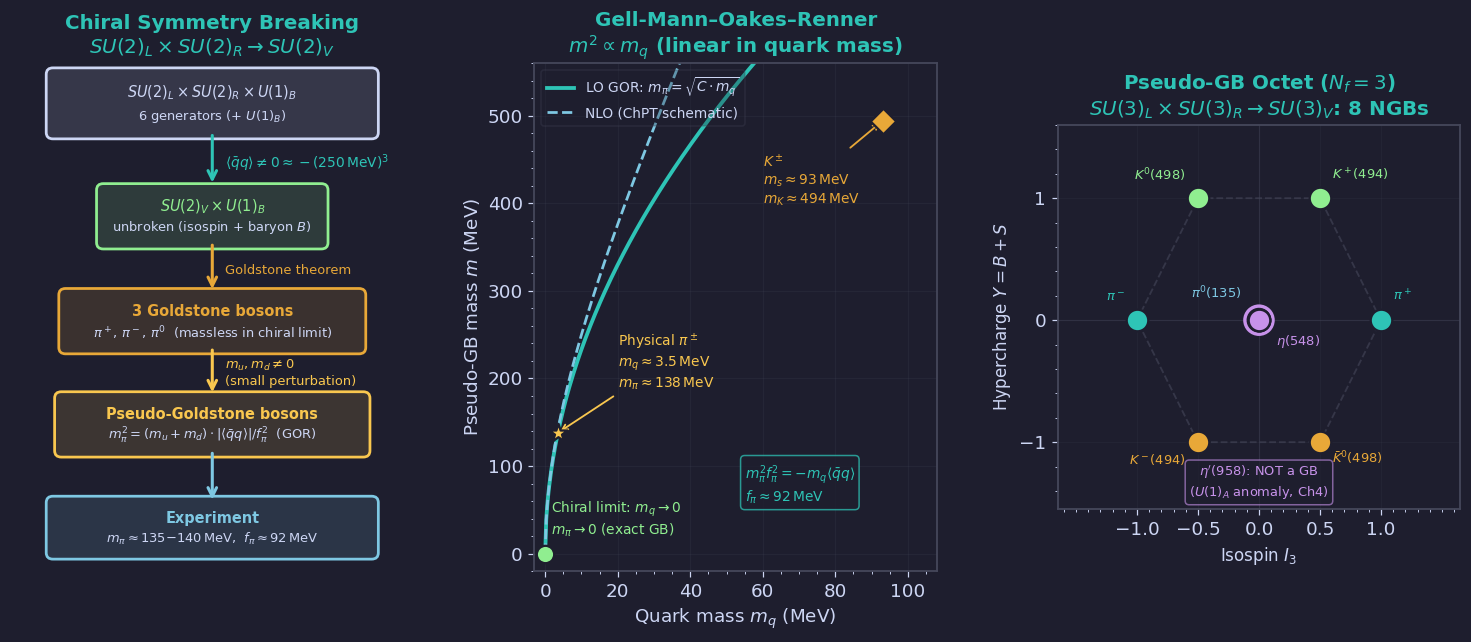

In [3]:
# fig02 uses a taller figure and individual subplots widths via gridspec
import matplotlib.gridspec as gridspec

fig = plt.figure(figsize=(17, 6.0))
fig.patch.set_facecolor(BG)
gs  = gridspec.GridSpec(1, 3, figure=fig, wspace=0.30)

# ── helpers ───────────────────────────────────────────────────────────────────
def fbox(ax, x, y, w, h, title, body, col, fontsize=9):
    """FancyBboxPatch with safe RGBA fill (no hex-string alpha hack)."""
    rect = FancyBboxPatch((x - w/2, y - h/2), w, h,
                          boxstyle='round,pad=0.08', lw=1.8,
                          edgecolor=col, facecolor=hex_alpha(col, 0.14))
    ax.add_patch(rect)
    ax.text(x, y + h*0.18, title, ha='center', va='center',
            color=col, fontsize=fontsize+0.5, fontweight='bold')
    ax.text(x, y - h*0.22, body,  ha='center', va='center',
            color=FG,  fontsize=fontsize-0.5)

def arr(ax, x1, y1, x2, y2, col, lbl='', lw=2.0):
    ax.annotate('', xy=(x2, y2), xytext=(x1, y1),
                arrowprops=dict(arrowstyle='->', color=col, lw=lw, mutation_scale=14))
    if lbl:
        ax.text((x1+x2)/2+0.1, (y1+y2)/2, lbl, color=col, fontsize=8.5)

# ── Left: symmetry breaking flow diagram ─────────────────────────────────────
ax = fig.add_subplot(gs[0])
ax.set_facecolor(BG)
ax.set_xlim(-0.3, 4.5)
ax.set_ylim(-0.5, 5.8)
ax.axis('off')
ax.set_title(r'Chiral Symmetry Breaking' + '\n'
             + r'$SU(2)_L\times SU(2)_R\to SU(2)_V$', color=TEAL)

fbox(ax, 2.1, 5.30, 3.8, 0.72,
     r'$SU(2)_L \times SU(2)_R \times U(1)_B$',
     r'6 generators (+ $U(1)_B$)', FG, fontsize=9)

arr(ax, 2.1, 4.94, 2.1, 4.28, TEAL)
ax.text(2.25, 4.50,
        r'$\langle\bar{q}q\rangle \neq 0$' + #'\n'
        r'$\approx -(250\,{\rm MeV})^3$', color=TEAL, fontsize=9)

fbox(ax, 2.1, 3.90, 2.6, 0.65,
     r'$SU(2)_V \times U(1)_B$',
     r'unbroken (isospin + baryon $B$)', GREEN, fontsize=9)

arr(ax, 2.1, 3.58, 2.1, 2.96, ORANGE)
ax.text(2.25, 3.18, r'Goldstone theorem', color=ORANGE, fontsize=8.5)

fbox(ax, 2.1, 2.60, 3.5, 0.65,
     r'3 Goldstone bosons',
     r'$\pi^+,\, \pi^-,\, \pi^0$  (massless in chiral limit)', ORANGE, fontsize=9)

arr(ax, 2.1, 2.28, 2.1, 1.68, YELLOW)
ax.text(2.25, 1.81,
        r'$m_u, m_d \neq 0$' + '\n' + r'(small perturbation)', color=YELLOW, fontsize=8.5)

fbox(ax, 2.1, 1.32, 3.6, 0.65,
     r'Pseudo-Goldstone bosons',
     r'$m_\pi^2 = (m_u+m_d)\cdot|\langle\bar{q}q\rangle|/f_\pi^2$  (GOR)',
     YELLOW, fontsize=9)

arr(ax, 2.1, 1.00, 2.1, 0.35, BLUE)

fbox(ax, 2.1, 0.04, 3.8, 0.62,
     r'Experiment',
     r'$m_\pi\approx 135{-}140\,{\rm MeV}$,  $f_\pi\approx 92\,{\rm MeV}$',
     BLUE, fontsize=9)

# ── Middle: GOR relation — FIXED: xlim extended to include kaon ───────────────
ax2 = fig.add_subplot(gs[1])
ax2.set_facecolor(BG)

# Physical parameters
mq_phys  = 3.5     # MeV  (avg u,d)
mpi_phys = 138.0   # MeV
C_GOR    = mpi_phys**2 / mq_phys

mq_s     = 93.0    # MeV  (strange quark mass)
mK_phys  = 494.0   # MeV

# Extend x range to include the kaon point
mq_range = np.linspace(0, 110, 400)   # 0 → 110 MeV (was 0→50, cut off kaon!)
mpi_GOR  = np.sqrt(np.maximum(C_GOR * mq_range, 0))
mpi_NLO  = np.sqrt(np.maximum(C_GOR * mq_range * (1 + 0.015*mq_range), 0))

ax2.plot(mq_range, mpi_GOR, color=TEAL, lw=2.5,
         label=r'LO GOR: $m_\pi = \sqrt{C\cdot m_q}$')
ax2.plot(mq_range, mpi_NLO, color=BLUE, lw=1.8, ls='--',
         label=r'NLO (ChPT schematic)')

# Chiral limit (origin)
ax2.scatter([0], [0], s=130, color=GREEN, zorder=6, edgecolors=BG, lw=1.5)
ax2.text(1.5, 22,
         r'Chiral limit: $m_q\to 0$' + '\n' + r'$m_\pi\to 0$ (exact GB)',
         color=GREEN, fontsize=9)

# Physical pion point
ax2.scatter([mq_phys], [mpi_phys], s=160, color=YELLOW,
            marker='*', zorder=6, edgecolors=BG, lw=1.5)
ax2.annotate(r'Physical $\pi^\pm$' + '\n'
             + r'$m_q\approx3.5\,{\rm MeV}$' + '\n'
             + r'$m_\pi\approx138\,{\rm MeV}$',
             xy=(mq_phys, mpi_phys), xytext=(20, 190),
             color=YELLOW, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=YELLOW, lw=1.2))

# Kaon / strange quark point (now visible inside xlim)
ax2.scatter([mq_s], [mK_phys], s=140, color=ORANGE,
            marker='D', zorder=6, edgecolors=BG, lw=1.5)
ax2.annotate(r'$K^\pm$' + '\n'
             + r'$m_s\approx93\,{\rm MeV}$' + '\n'
             + r'$m_K\approx494\,{\rm MeV}$',
             xy=(mq_s, mK_phys), xytext=(60, 400),
             color=ORANGE, fontsize=9,
             arrowprops=dict(arrowstyle='->', color=ORANGE, lw=1.2))

# GOR formula box (moved out of data region)
ax2.text(55, 60,
         r'$m_\pi^2 f_\pi^2 = -m_q\langle\bar{q}q\rangle$' + '\n'
         r'$f_\pi \approx 92\,{\rm MeV}$',
         color=TEAL, fontsize=9,
         bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.75))

ax2.set_xlabel(r'Quark mass $m_q$ (MeV)')
ax2.set_ylabel(r'Pseudo-GB mass $m$ (MeV)')
ax2.set_title('Gell-Mann–Oakes–Renner\n'
              + r'$m^2 \propto m_q$ (linear in quark mass)', color=TEAL)
ax2.set_xlim(-3, 108)
ax2.set_ylim(-20, 560)
ax2.legend(fontsize=9, labelcolor=FG, loc='upper left')
ax2.grid(True, alpha=0.2)

# ── Right: pseudo-Goldstone boson octet — FIXED: π0 and η separated ──────────
ax3 = fig.add_subplot(gs[2])
ax3.set_facecolor(BG)
ax3.set_aspect('equal')

# Meson octet: (I3, Y, name, mass, colour, label_offset_dx, label_offset_dy, ha)
mesons = [
    (+1.0,  0.0, r'$\pi^+$',        135, TEAL,   +0.10, +0.16, 'left'),
    (-1.0,  0.0, r'$\pi^-$',        135, TEAL,   -0.10, +0.16, 'right'),
    ( 0.0,  0.0, r'$\pi^0$(135)',   135, BLUE,   -0.14, +0.18, 'right'),   # shifted left
    ( 0.0,  0.0, r'$\eta$(548)',    548, PURPLE, +0.14, -0.20, 'left'),    # shifted right+below
    (+0.5, +1.0, r'$K^+$(494)',     494, GREEN,  +0.10, +0.15, 'left'),
    (-0.5, +1.0, r'$K^0$(498)',     498, GREEN,  -0.10, +0.15, 'right'),
    (+0.5, -1.0, r'$\bar{K}^0$(498)',498,ORANGE, +0.10, -0.18, 'left'),
    (-0.5, -1.0, r'$K^-$(494)',     494, ORANGE, -0.10, -0.18, 'right'),
]

# Hexagon outline
hex_I3 = [+1, +0.5, -0.5, -1, -0.5, +0.5, +1]
hex_Y  = [ 0, +1,   +1,    0,  -1,   -1,    0]
ax3.plot(hex_I3, hex_Y, color=EDGE, lw=1.2, ls='--', alpha=0.6)

for (I3, Y, name, mass, col, dx, dy, ha) in mesons:
    ax3.scatter([I3], [Y], s=200, color=col, zorder=5,
                edgecolors=BG, lw=1.5)
    ax3.text(I3+dx, Y+dy, name, color=col, fontsize=8.5, ha=ha)

# Axes
ax3.axhline(0, color=EDGE, lw=0.8, ls='-', alpha=0.4)
ax3.axvline(0, color=EDGE, lw=0.8, ls='-', alpha=0.4)

ax3.set_xlabel(r'Isospin $I_3$', fontsize=11)
ax3.set_ylabel(r'Hypercharge $Y = B + S$', fontsize=11)
ax3.set_title(r'Pseudo-GB Octet ($N_f=3$)' + '\n'
              + r'$SU(3)_L\times SU(3)_R\to SU(3)_V$: 8 NGBs', color=TEAL)
ax3.set_xlim(-1.65, 1.65)
ax3.set_ylim(-1.55, 1.60)

# η′ singlet — circle (not a GB due to U(1)_A anomaly)
ax3.scatter([0], [0], s=340, color=PURPLE, zorder=4,
            edgecolors=PURPLE, lw=2.2, facecolors='none')
ax3.text(0.0, -1.44,
         r"$\eta'$(958): NOT a GB" + '\n' + r'($U(1)_A$ anomaly, Ch4)',
         ha='center', color=PURPLE, fontsize=8.5,
         bbox=dict(boxstyle='round', fc=BG, ec=PURPLE, alpha=0.6))

ax3.set_xticks([-1, -0.5, 0, 0.5, 1])
ax3.set_yticks([-1, 0, 1])
ax3.grid(True, alpha=0.15)

save('fig02_chiral_breaking.png', fig)


---
## fig03 · QCD Potential and Hadron Spectrum (§3.4)

**Left**: Cornell potential $V(r) = -4\alpha_s/3r + \sigma r$ with Coulomb and linear regimes  
**Middle**: Charmonium $c\bar{c}$ energy levels in the Cornell potential  
**Right**: Colour-singlet combinations — meson, baryon, and glueball schematic

  saved -> figures/ch03/fig03_confinement.png


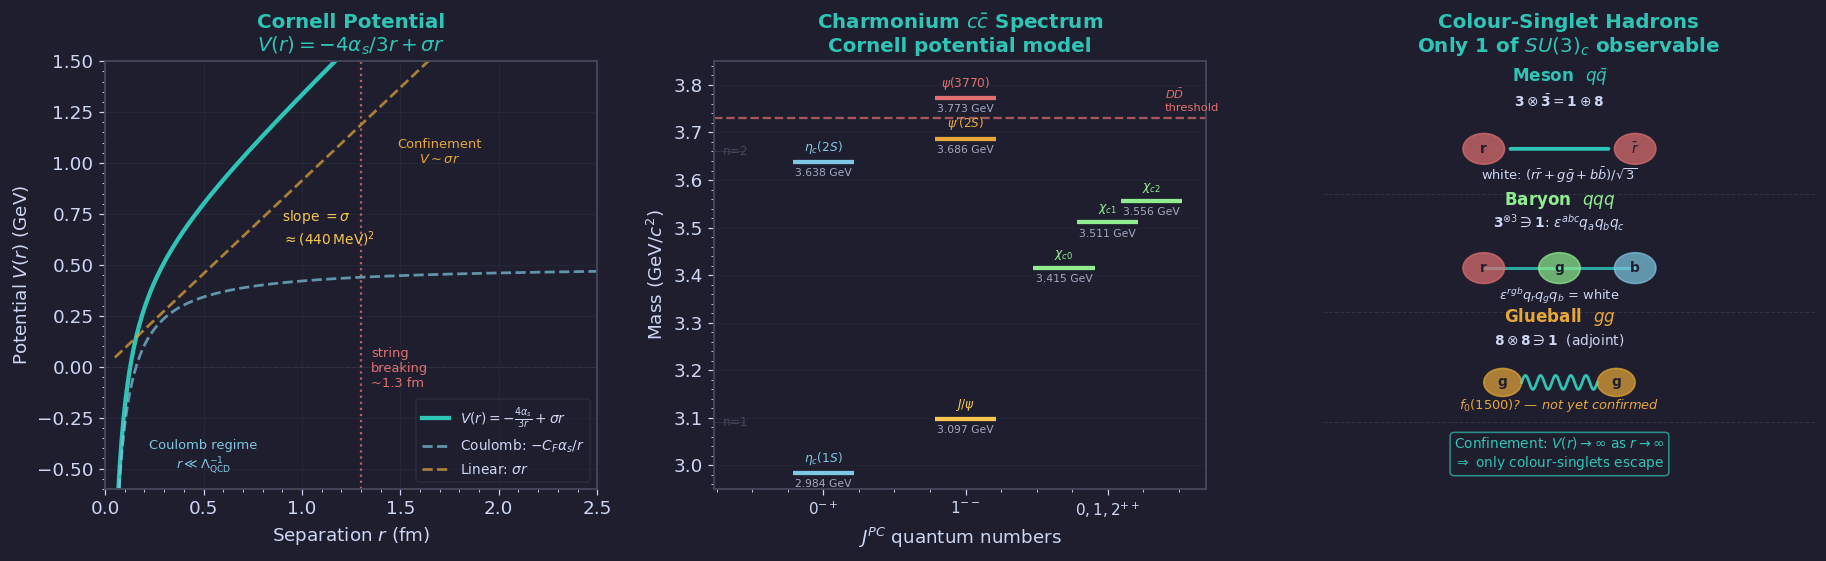

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5.5))
fig.patch.set_facecolor(BG)

# ── Left: Cornell potential ───────────────────────────────────────────────────
ax = axes[0]
ax.set_facecolor(BG)

alpha_s_val = 0.3
CF          = 4/3
sigma       = 0.18    # GeV^2
r_fm        = np.linspace(0.05, 2.5, 500)
r_GeV       = r_fm / 0.197

V_coulomb = -CF * alpha_s_val / r_GeV
V_linear  =  sigma * r_GeV
V_total   = V_coulomb + V_linear + 0.5

ax.plot(r_fm, V_total,          color=TEAL,   lw=2.8,
        label=r'$V(r) = -\frac{4\alpha_s}{3r} + \sigma r$')
ax.plot(r_fm, V_coulomb + 0.5,  color=BLUE,   lw=1.8, ls='--', alpha=0.7,
        label=r'Coulomb: $-C_F\alpha_s/r$')
ax.plot(r_fm, V_linear,         color=ORANGE, lw=1.8, ls='--', alpha=0.7,
        label=r'Linear: $\sigma r$')

r_break = 1.3
ax.axvline(r_break, color=RED, lw=1.5, ls=':', alpha=0.8)
ax.text(r_break+0.05, -0.1, 'string\nbreaking\n~1.3 fm', color=RED, fontsize=8.5)

ax.text(0.50, -0.50, r'Coulomb regime' + '\n' + r'$r\ll\Lambda_{\rm QCD}^{-1}$',
        color=BLUE,   fontsize=8.5, ha='center')
ax.text(1.70, 1.00,  r'Confinement' +   '\n' + r'$V\sim\sigma r$',
        color=ORANGE, fontsize=8.5, ha='center')

ax.annotate('',
    xy=(2.0, V_total[np.argmin(np.abs(r_fm-2.0))]),
    xytext=(2.0, V_total[np.argmin(np.abs(r_fm-1.2))]),
    arrowprops=dict(arrowstyle='<->', color=YELLOW, lw=1.5))
ax.text(0.9, 0.6,
        r'slope $=\sigma$' + '\n' + r'$\approx(440\,{\rm MeV})^2$',
        color=YELLOW, fontsize=9)

ax.set_xlabel(r'Separation $r$ (fm)')
ax.set_ylabel(r'Potential $V(r)$ (GeV)')
ax.set_title('Cornell Potential\n' + r'$V(r) = -4\alpha_s/3r + \sigma r$', color=TEAL)
ax.set_xlim(0, 2.5);  ax.set_ylim(-0.6, 1.5)
ax.axhline(0, color=EDGE, lw=0.8, ls='--', alpha=0.4)
ax.legend(fontsize=9, labelcolor=FG, loc='lower right')
ax.grid(True, alpha=0.2)

# ── Middle: charmonium spectrum — FULL REWRITE (no text overlap) ───────────────
ax2 = axes[1]
ax2.set_facecolor(BG)

# Charmonium states — organised by J^PC column and n radial quantum number
# (col_x, mass_GeV, name, colour)
# Three distinct x-columns: pseudo-scalar (0^-+), vector (1^--), tensor (0,1,2^++)
states = [
    # pseudo-scalar 0^-+
    (0.50, 2.984,  r'$\eta_c(1S)$',  BLUE),
    (0.50, 3.638,  r'$\eta_c(2S)$',  BLUE),
    # vector 1^--
    (1.80, 3.097,  r'$J/\psi$',      YELLOW),
    (1.80, 3.686,  r"$\psi'(2S)$",   ORANGE),
    (1.80, 3.773,  r'$\psi(3770)$',  RED),
    # P-wave states — separate sub-columns to spread labels
    (2.70, 3.415,  r'$\chi_{c0}$',   GREEN),
    (3.10, 3.511,  r'$\chi_{c1}$',   GREEN),
    (3.50, 3.556,  r'$\chi_{c2}$',   GREEN),
]

DD_threshold = 2 * 1.865   # D meson
ax2.axhline(DD_threshold, color=RED, lw=1.5, ls='--', alpha=0.7)
ax2.text(3.62, DD_threshold+0.012,
         r'$D\bar{D}$' + '\n' + 'threshold',
         color=RED, fontsize=7.5, va='bottom', ha='left')

LEV_HALF = 0.28   # half-width of energy-level tick marks
for (x, m, name, col) in states:
    ax2.hlines(m, x-LEV_HALF, x+LEV_HALF, color=col, lw=2.8, zorder=4)
    # Mass label above the line
    ax2.text(x, m+0.013, name,
             ha='center', va='bottom', color=col, fontsize=8.0)
    # Numerical mass below
    ax2.text(x, m-0.013, f'{m:.3f} GeV',
             ha='center', va='top',    color=FG,  fontsize=7.0, alpha=0.75)

# n=1, n=2 radial labels on the left margin
for (y, lbl) in [(3.09, 'n=1'), (3.66, 'n=2')]:
    ax2.text(-0.42, y, lbl, color=EDGE, fontsize=8, va='center', ha='left')
    ax2.axhline(y, xmin=0.0, xmax=0.06, color=EDGE, lw=0.7, alpha=0.5)

# x-axis column labels
ax2.set_xticks([0.5, 1.8, 3.1])
ax2.set_xticklabels([r'$0^{-+}$', r'$1^{--}$', r'$0,1,2^{++}$'], fontsize=10)

ax2.set_xlim(-0.5, 4.0)
ax2.set_ylim(2.95, 3.85)
ax2.set_ylabel(r'Mass (GeV/$c^2$)')
ax2.set_xlabel(r'$J^{PC}$ quantum numbers')
ax2.set_title(r'Charmonium $c\bar{c}$ Spectrum' + '\n'
              + 'Cornell potential model', color=TEAL)
ax2.grid(True, alpha=0.15, axis='y')

# ── Right: colour-singlet hadrons ─────────────────────────────────────────────
ax3 = axes[2]
ax3.set_facecolor(BG)
ax3.set_xlim(-0.2, 5.0)
ax3.set_ylim(-0.3, 5.8)
ax3.axis('off')
ax3.set_title('Colour-Singlet Hadrons\n'
              + r'Only $\mathbf{1}$ of $SU(3)_c$ observable', color=TEAL)

def quark_circle(ax, x, y, col, label, r=0.22):
    ax.add_patch(Circle((x, y), r, color=col, alpha=0.7, zorder=4))
    ax.text(x, y, label, ha='center', va='center',
            color=BG, fontsize=9, fontweight='bold', zorder=5)

def curly(ax, x1, y1, x2, y2, col, amp=0.10, n=5):
    t   = np.linspace(0, 1, 300)
    ang = np.arctan2(y2-y1, x2-x1)
    L   = np.hypot(x2-x1, y2-y1)
    s   = t * L
    p   = amp * np.sin(2*np.pi*n*t)
    ax.plot(x1 + s*np.cos(ang) - p*np.sin(ang),
            y1 + s*np.sin(ang) + p*np.cos(ang),
            color=col, lw=1.8)

# --- Meson ---
ax3.text(2.3, 5.50, r'Meson  $q\bar{q}$', ha='center',
         color=TEAL, fontsize=11, fontweight='bold')
ax3.text(2.3, 5.16,
         r'$\mathbf{3}\otimes\bar{\mathbf{3}} = \mathbf{1}\oplus\mathbf{8}$',
         ha='center', color=FG, fontsize=9)
quark_circle(ax3, 1.5, 4.55, RED, 'r')
quark_circle(ax3, 3.1, 4.55, RED, r'$\bar{r}$')
ax3.annotate('', xy=(2.85, 4.55), xytext=(1.75, 4.55),
             arrowprops=dict(arrowstyle='-', color=TEAL, lw=2.5,
                             connectionstyle='arc3,rad=0.0'))
ax3.text(2.3, 4.10,
         r'white: $(r\bar{r}+g\bar{g}+b\bar{b})/\sqrt{3}$',
         ha='center', color=FG, fontsize=8.5)

ax3.axhline(3.90, color=EDGE, lw=0.7, ls='--', alpha=0.5)

# --- Baryon ---
ax3.text(2.3, 3.75, r'Baryon  $qqq$', ha='center',
         color=GREEN, fontsize=11, fontweight='bold')
ax3.text(2.3, 3.42,
         r'$\mathbf{3}^{\otimes3}\ni\mathbf{1}$: $\varepsilon^{abc}q_aq_bq_c$',
         ha='center', color=FG, fontsize=9)
quark_circle(ax3, 1.5, 2.85, RED,   'r')
quark_circle(ax3, 2.3, 2.85, GREEN, 'g')
quark_circle(ax3, 3.1, 2.85, BLUE,  'b')
for (x1,y1),(x2,y2) in [((1.5,2.85),(2.3,2.85)),
                          ((2.3,2.85),(3.1,2.85)),
                          ((1.5,2.85),(3.1,2.85))]:
    ax3.plot([x1,x2],[y1,y2], color=TEAL, lw=2.0, alpha=0.6, zorder=3)
ax3.text(2.3, 2.40, r'$\varepsilon^{rgb}q_rq_gq_b$ = white',
         ha='center', color=FG, fontsize=8.5)

ax3.axhline(2.22, color=EDGE, lw=0.7, ls='--', alpha=0.5)

# --- Glueball ---
ax3.text(2.3, 2.08, r'Glueball  $gg$', ha='center',
         color=ORANGE, fontsize=11, fontweight='bold')
ax3.text(2.3, 1.76,
         r'$\mathbf{8}\otimes\mathbf{8}\ni\mathbf{1}$  (adjoint)',
         ha='center', color=FG, fontsize=9)
quark_circle(ax3, 1.7, 1.22, ORANGE, 'g', r=0.20)
quark_circle(ax3, 2.9, 1.22, ORANGE, 'g', r=0.20)
curly(ax3, 1.90, 1.22, 2.70, 1.22, TEAL)
ax3.text(2.3, 0.84, r'$f_0(1500)$? — not yet confirmed',
         ha='center', color=ORANGE, fontsize=8.5, style='italic')

ax3.axhline(0.66, color=EDGE, lw=0.7, ls='--', alpha=0.5)
ax3.text(2.3, 0.02,
         r'Confinement: $V(r)\to\infty$ as $r\to\infty$' + '\n'
         r'$\Rightarrow$ only colour-singlets escape',
         ha='center', color=TEAL, fontsize=9,
         bbox=dict(boxstyle='round', fc=BG, ec=TEAL, alpha=0.7))

plt.tight_layout(pad=1.8)
save('fig03_confinement.png', fig)


In [5]:
import zipfile
import os

# ── 1. Zip all generated figures ──────────────────────────────────────────
ZIP_NAME = 'sm_ch03_figures.zip'
OUTDIR   = 'figures/ch03'

with zipfile.ZipFile(ZIP_NAME, 'w', compression=zipfile.ZIP_DEFLATED) as zf:
    for fname in sorted(os.listdir(OUTDIR)):
        if fname.endswith('.png'):
            fpath = os.path.join(OUTDIR, fname)
            zf.write(fpath, arcname=fname)
            print(f'  added: {fname}  ({os.path.getsize(fpath)//1024} KB)')

print(f'\nArchive ready: {ZIP_NAME}  ({os.path.getsize(ZIP_NAME)//1024} KB)')

# ── 2. Trigger browser download (Colab only) ──────────────────────────────
try:
    from google.colab import files
    files.download(ZIP_NAME)
    print('Download started — check your browser.')
except ImportError:
    print(f'Not running in Colab.  Zip saved at: {os.path.abspath(ZIP_NAME)}')

  added: fig01_running_coupling.png  (279 KB)
  added: fig02_chiral_breaking.png  (271 KB)
  added: fig03_confinement.png  (269 KB)

Archive ready: sm_ch03_figures.zip  (782 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download started — check your browser.


---
## All figures generated

| File | Used in slide |
|------|---------------|
| `figures/ch03/fig01_running_coupling.png` | §3.2 · Asymptotic Freedom |
| `figures/ch03/fig02_chiral_breaking.png`  | §3.3 · Chiral Symmetry |
| `figures/ch03/fig03_confinement.png`      | §3.4 · Hadrons & Confinement |

Copy the `figures/` folder next to `sm_ch03_slides.qmd` before rendering with Quarto.